In [1]:
# Importing relevant modules

%matplotlib inline

from __future__ import division

from collections import OrderedDict
from scipy.stats import binom
import sys
import os
import matplotlib.pyplot as plt
import math
import numpy as np

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import xpsi
from xpsi import PostProcessing

# choose a seed for the notebook if you want caching to be useful
# and the notebook exactly reproducible
PostProcessing.set_random_seed(42)

from xpsi.global_imports import gravradius, _2pi
from xpsi.utilities.ProjectionTool import plot_projection_general
#from xpsi.utilities.BackgroundTools import readSummary, plotBackgroundSpectrum
from xpsi.utilities.ConvergenceTool import plotConvergence

/=============================================\
| X-PSI: X-ray Pulse Simulation and Inference |
|---------------------------------------------|
|               Version: 3.5.0b1              |
|---------------------------------------------|
|      https://xpsi-group.github.io/xpsi      |
\=============================================/

Imported GetDist version: 1.7.7
Imported nestcheck version: 0.2.1


/home/yves/envs/xpsi_hack/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import main as ST

Setting channels for event data...
Channels set.
Setting channels for loaded instrument response (sub)matrix...
Channels set.
An empty subspace was created. This is normal behavior - no parameters were supplied.
Creating parameter:
    > Named "phase_shift" with fixed value 0.000e+00.
    > The phase shift for the signal, a periodic parameter [cycles].
Creating parameter:
    > Named "frequency" with fixed value 3.140e+02.
    > Spin frequency [Hz].
Creating parameter:
    > Named "mass" with bounds [1.000e+00, 1.600e+00].
    > Gravitational mass [solar masses].
Creating parameter:
    > Named "radius" with bounds [1.000e+01, 1.300e+01].
    > Coordinate equatorial radius [km].
Creating parameter:
    > Named "distance" with bounds [5.000e-01, 2.000e+00].
    > Earth distance [kpc].
Creating parameter:
    > Named "cos_inclination" with bounds [0.000e+00, 1.000e+00].
    > Cosine of Earth inclination to rotation axis.
Creating parameter:
    > Named "super_colatitude" with bounds [1.0

In [3]:
# Settings names, bounds and labels
ST.names=['mass','radius','distance','cos_inclination','p__phase_shift',
          'p__super_colatitude','p__super_radius','p__super_temperature']

# We need to use the same bounds used during sampling
# They can be changed in the posterior using the param_plot_lims parameter, for example it can be set to {'radius': (9.0,12.0)} to restrict the plotting of the radius.
ST.bounds = {'mass':(1.0,1.6),
             'radius':(10,13),
             'distance':(0.5,2.0),
             'cos_inclination':(0,1),
             'p__phase_shift':(-0.25, 0.75),
             'p__super_colatitude':(0.001, math.pi/2 - 0.001),
             'p__super_radius':(0.001, math.pi/2.0 - 0.001),
             'p__super_temperature':(6., 7.)}

# Now the labels
ST.labels = {'mass': r"M\;\mathrm{[M}_{\odot}\mathrm{]}",
              'radius': r"R_{\mathrm{eq}}\;\mathrm{[km]}",
              'distance': r"D \;\mathrm{[kpc]}",
              'cos_inclination': r"\cos(i)",
              'p__phase_shift': r"\phi_{p}\;\mathrm{[cycles]}",
              'p__super_colatitude': r"\Theta_{\mathrm{spot}}\;\mathrm{[rad]}",
              'p__super_radius': r"\zeta_{\mathrm{spot}}\;\mathrm{[rad]}",
              'p__super_temperature': r"\mathrm{log10}(T_{\mathrm{spot}}\;[\mathrm{K}])"}

# Optional shorter labels (here without units) for the 2D panels when labels_2D=True
ST.short_labels = {'mass': r"M",
                   'radius': r"R_{\mathrm{eq}}",
                   'distance': r"D",
                   'cos_inclination': r"\cos(i)",
                   'p__phase_shift': r"\phi_{p}",
                   'p__super_colatitude': r"\Theta_{\mathrm{spot}}",
                   'p__super_radius': r"\zeta_{\mathrm{spot}}",
                   'p__super_temperature': r"\mathrm{log10}(T_{\mathrm{spot}})"}

In [4]:
ST.names +=['compactness']
ST.bounds['compactness']=(gravradius(1.0)/16.0, 1.0/3.0)
ST.labels['compactness']= r"M/R_{\mathrm{eq}}"
ST.short_labels['compactness']= r"M/R_{\mathrm{eq}}"

In [5]:
getdist_kde_settings = {'ignore_rows': 0,
                         'min_weight_ratio': 1.0e-10,
                         'contours': [0.683, 0.954, 0.997],
                         'credible_interval_threshold': 0.001,
                         'range_ND_contour': 0,
                         'range_confidence': 0.001,
                         'fine_bins': 1024,
                         'smooth_scale_1D': 0.4,
                         'num_bins': 100,
                         'boundary_correction_order': 1,
                         'mult_bias_correction_order': 1,
                         'smooth_scale_2D': 0.4,
                         'max_corr_2D': 0.99,
                         'fine_bins_2D': 512,
                         'num_bins_2D': 40}

In [6]:
# Our case:
ST.truths={'mass': 1.4,                               # Mass in solar Mass
          'radius': 12.,                              # Equatorial radius in km
          'distance': 1.0,                            # Distance in kpc
          'cos_inclination': math.cos(60*np.pi/180),  # Cosine of Earth inclination to rotation axis
          'p__phase_shift': 0.0,                    # Phase shift
          'p__super_colatitude': 70*np.pi/180,      # Colatitude of the centre of the superseding region
          'p__super_radius': 0.75,                  # Angular radius of the (circular) superseding region
          'p__super_temperature':6.7}               # Temperature in log

ST.truths['compactness']=gravradius(ST.truths['mass'])/ST.truths['radius']

In [7]:
ST.runs = xpsi.Runs.load_runs(ID='ST',
                               run_IDs=['Multinest','PT_MCMC_full'],
                               roots=['ST_live_1000_eff_0.3_seed0','ST_ptemcee'],
                               base_dirs=['../Outputs/',
                                         '../Outputs/'],
                               use_nestcheck=[False]*2,#[True]*2,
                               kde_settings=getdist_kde_settings,
                               likelihood=ST.likelihood,
                               names=ST.names,
                               bounds=ST.bounds,
                               labels=ST.labels,
                               truths=ST.truths, 
                               implementation='multinest',
                               overwrite_transformed=True)



Change output files to .npy to speed up post-processing
Change output files to .npy to speed up post-processing


Executing posterior density estimation...
Curating set of runs for posterior plotting...
Run set curated.
Constructing lower-triangle posterior density plot via Gaussian KDE:
plotting:  ['mass', 'radius']
plotting:  ['mass', 'distance']
plotting:  ['mass', 'cos_inclination']
plotting:  ['mass', 'p__phase_shift']
plotting:  ['mass', 'p__super_colatitude']
plotting:  ['mass', 'p__super_radius']
plotting:  ['mass', 'p__super_temperature']
plotting:  ['mass', 'compactness']
plotting:  ['radius', 'distance']
plotting:  ['radius', 'cos_inclination']
plotting:  ['radius', 'p__phase_shift']
plotting:  ['radius', 'p__super_colatitude']
plotting:  ['radius', 'p__super_radius']
plotting:  ['radius', 'p__super_temperature']
plotting:  ['radius', 'compactness']
plotting:  ['distance', 'cos_inclination']
plotting:  ['distance', 'p__phase_shift']
plotting:  ['distance', 'p__super_colatitude']
plotting:  ['distance', 'p__super_radius']
plotting:  ['distance', 'p__super_temperature']
plotting:  ['dista

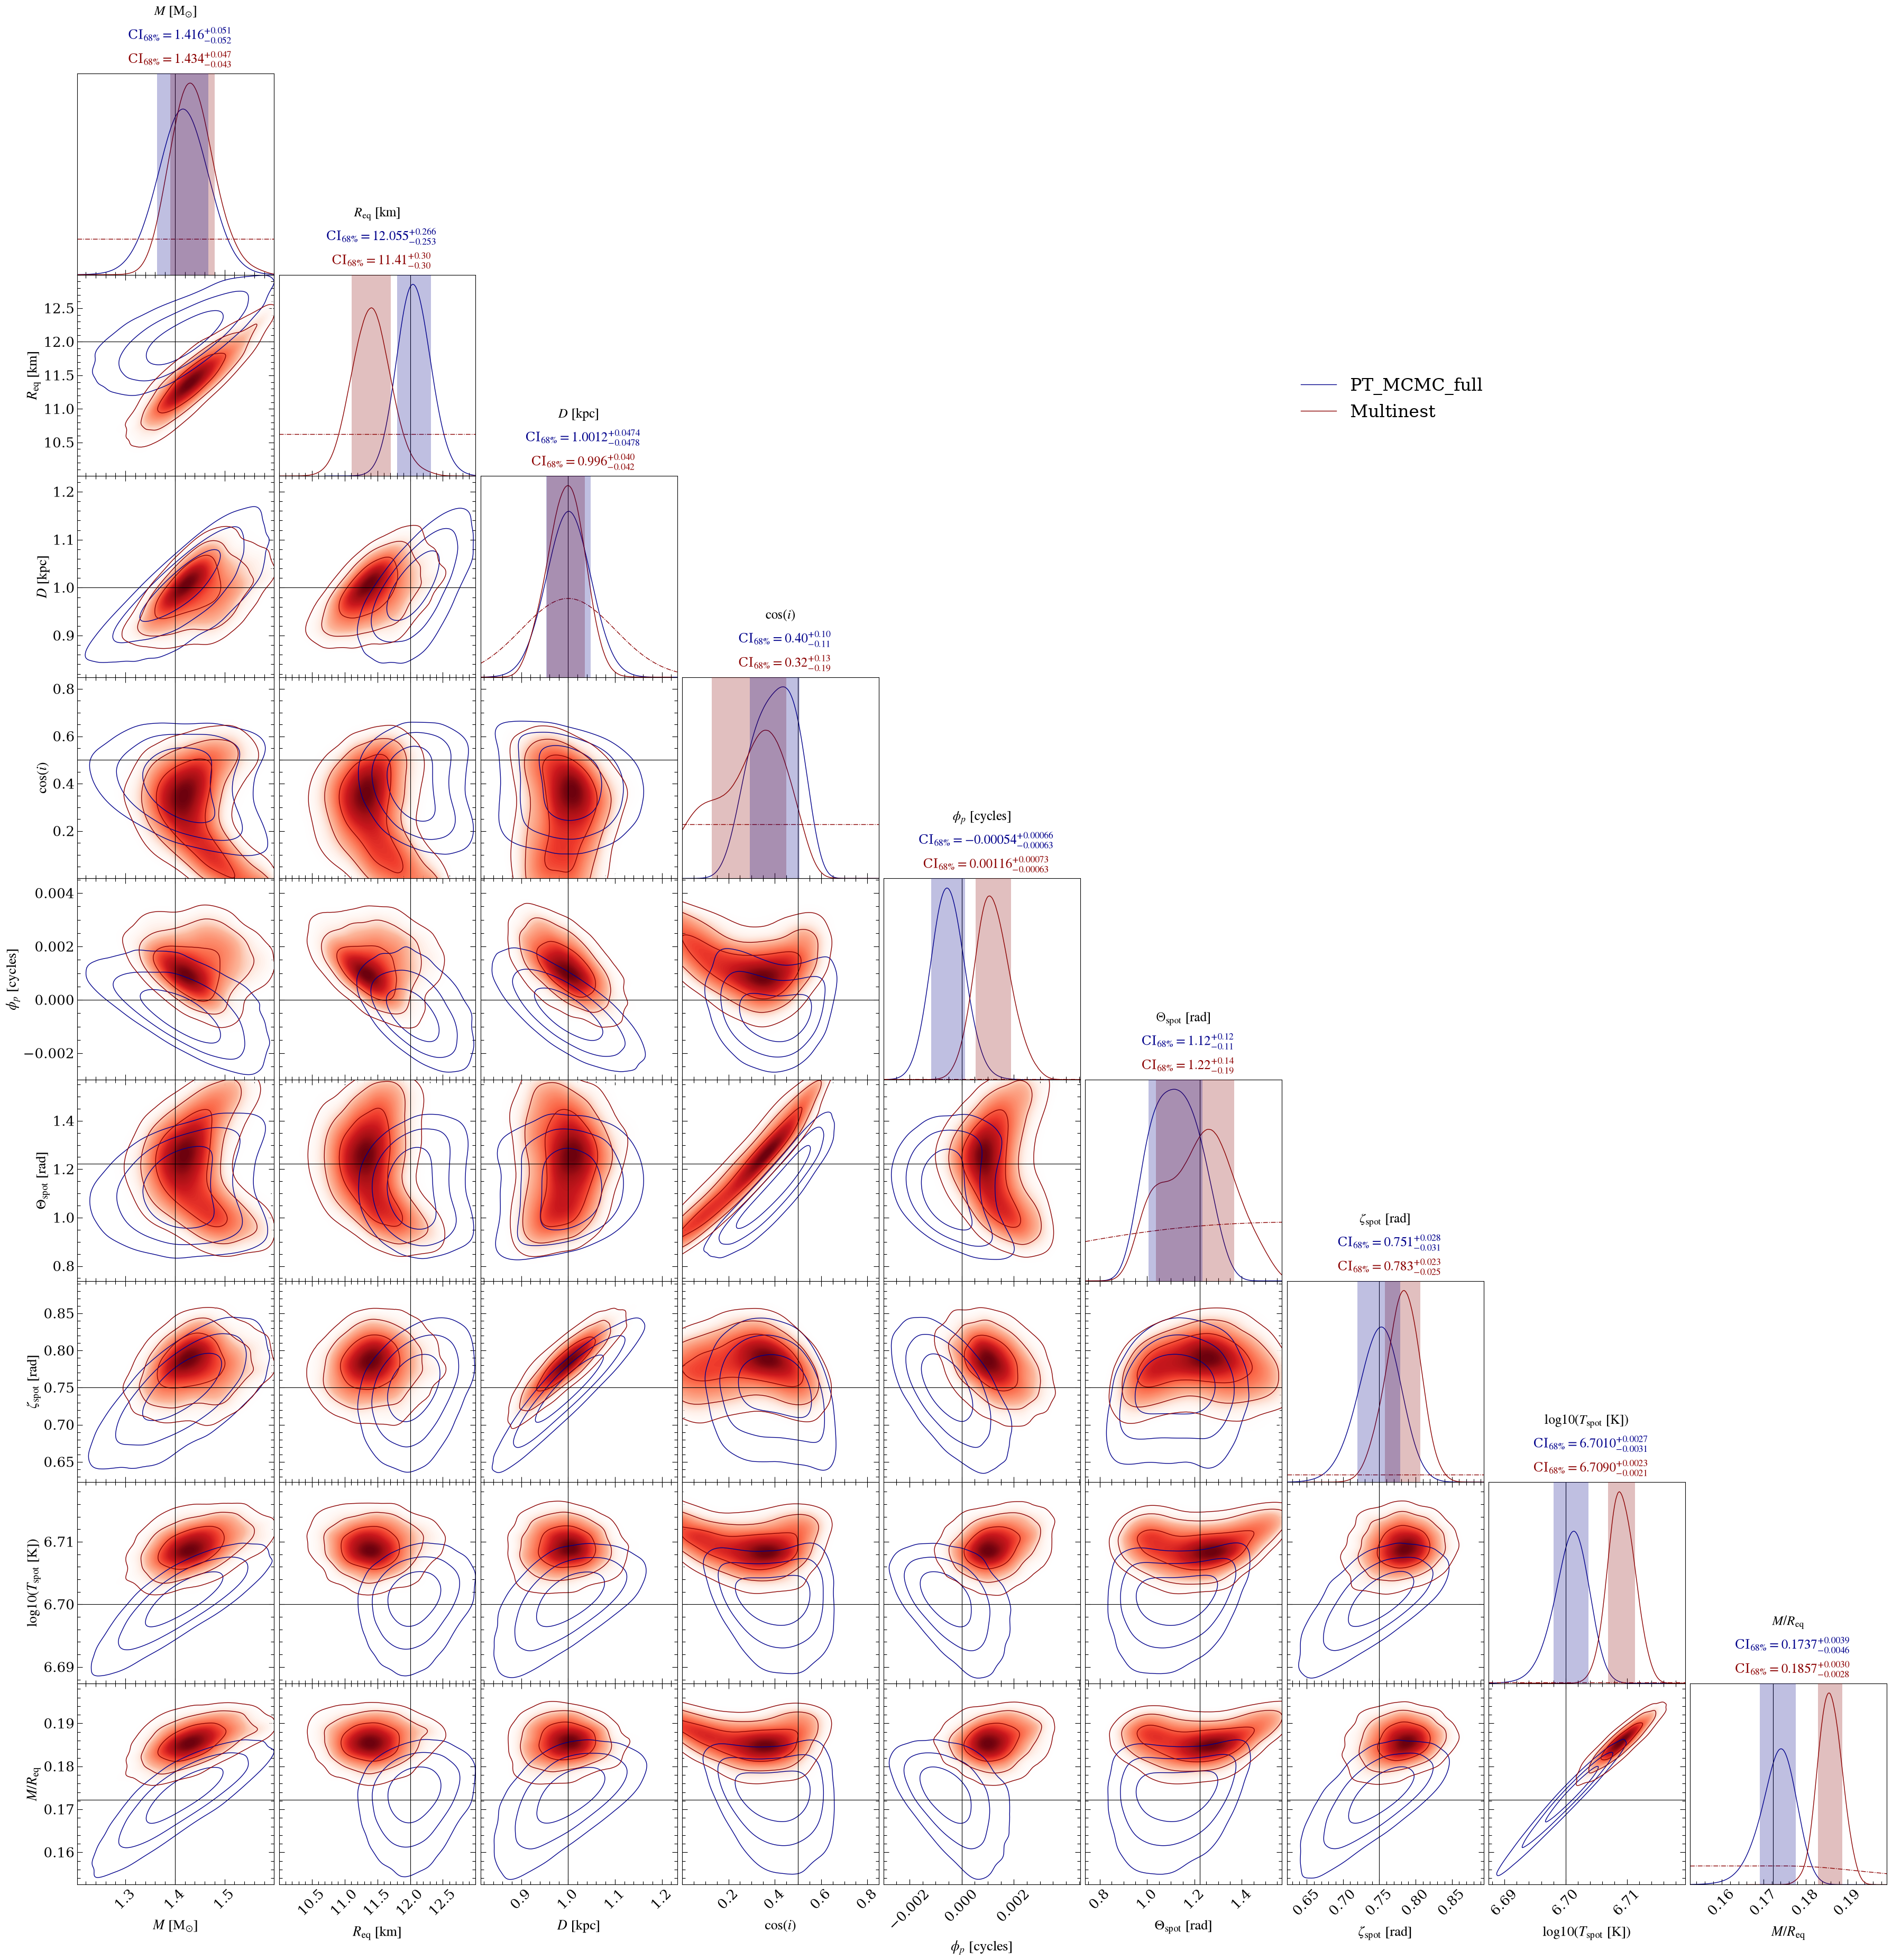

In [8]:
pp = xpsi.PostProcessing.CornerPlotter([ST.runs])
_ = pp.plot(
     params=ST.names,
     IDs=OrderedDict([('ST', ['Multinest','PT_MCMC_full',]),]),
     prior_density=True,
     KL_divergence=True,
     ndraws=5e4,
     combine=False, combine_all=True, only_combined=False, overwrite_combined=True,
     param_plot_lims={},
     bootstrap_estimators=False,
     bootstrap_density=False,
     n_simulate=200,
     crosshairs=True,
     write=False,
     ext='.png',
     maxdots=3000,
     root_filename='run',
     credible_interval_1d=True,
     credible_interval_1d_all_show=True, # To show credible intervals for all runs/models
     show_vband=[0,1],                   # To list which vertical colored bands are shown in 1D-posteriors
                                         #  0 for run_seed0,  1 for run_seed42
     annotate_credible_interval=True,
     compute_all_intervals=False,
     sixtyeight=True,
     axis_tick_x_rotation=45.0,
     num_plot_contours=3,
     subplot_size=4.0,
     legend_corner_coords=(0.675,0.8),
     legend_frameon=False,
     scale_attrs=OrderedDict([('legend_fontsize', 2.0),
                              ('axes_labelsize', 1.35),
                              ('axes_fontsize', 'axes_labelsize'),
                             ]
                            ),
     colormap='Reds',
     shaded=-1,
     rasterized_shade=True,
     no_ylabel=True,
     no_ytick=True,
     lw=1.0,
     lw_1d=1.0,
     filled=False,
     normalize=True,
     veneer=True,
     tqdm_kwargs={'disable': False},
     lengthen=2.0,
     embolden=1.0,
     nx=500)

In [17]:
mulinest =  np.loadtxt('../Outputs/ST_live_1000_eff_0.3_seed0.txt')
pt_mcmc_full =  np.loadtxt('../Outputs/ST_ptemcee.txt')

In [18]:
#pt_mcmc_full = pt_mcmc_full[pt_mcmc_full[:, 1] != 0]

In [19]:
pt_mcmc_full.shape

(300000, 10)

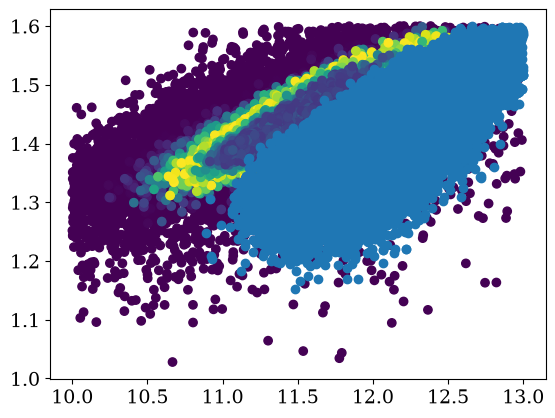

In [12]:
plt.scatter(mulinest[:,3], mulinest[:,2], c=mulinest[:,0])
plt.scatter(pt_mcmc_full[:,3], pt_mcmc_full[:,2])

In [13]:
pt_mcmc_full.shape

(300000, 10)

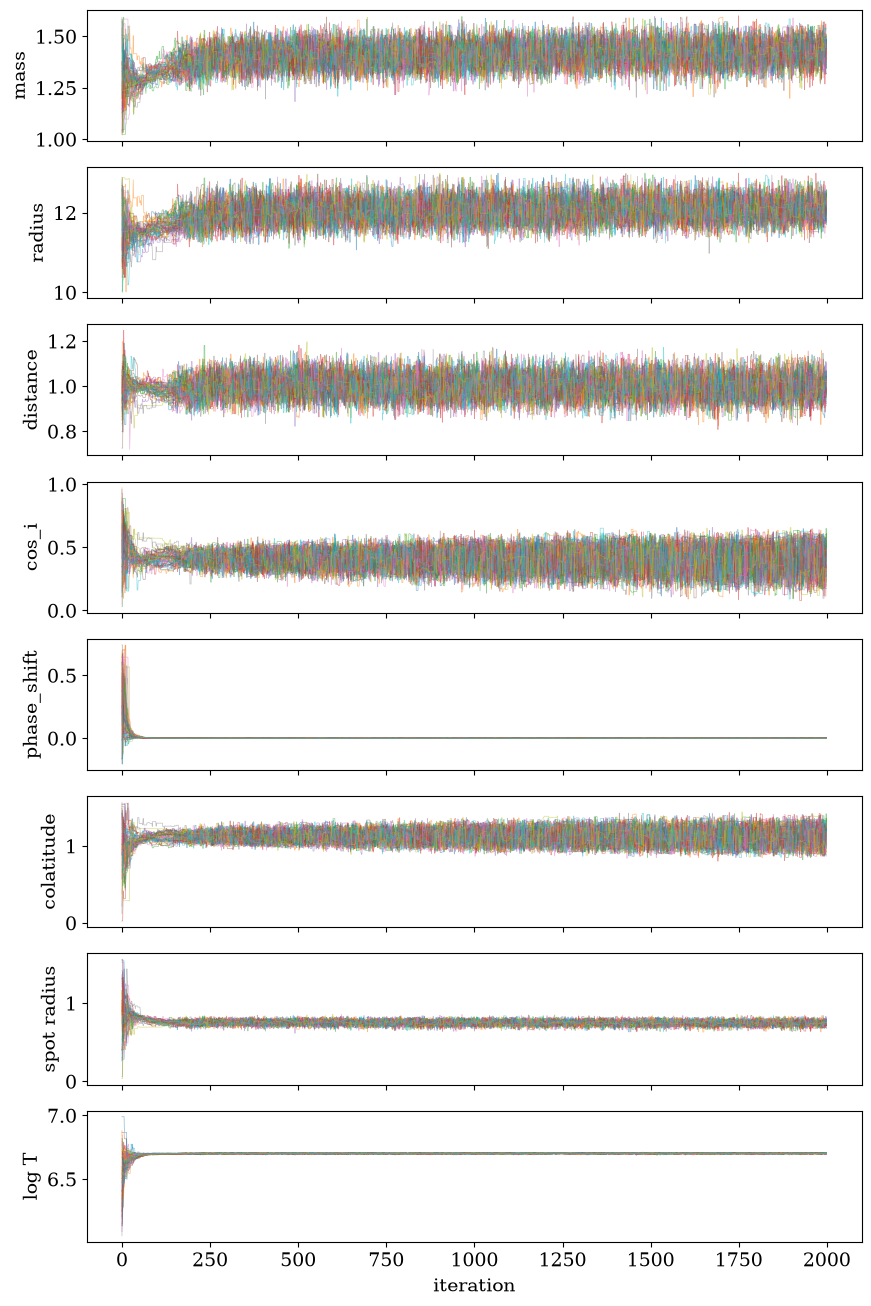

In [14]:
import numpy as np
import matplotlib.pyplot as plt

d = np.load('../Outputs/ST_ptemcee_ptemcee.npz')
chain = d['chain']        # shape (ntemps, nwalkers, nsteps, ndims) = (2, 1000, 2000, 8)
logl  = d['loglikelihood']  # shape (2, 1000, 2000)

cold = chain[0]           # cold chain (beta = 1): (walkers, iterations, parameters)

names = ['mass', 'radius', 'distance', 'cos_i',
         'phase_shift', 'colatitude', 'spot radius', 'log T']
fig, axes = plt.subplots(8, 1, figsize=(10, 16), sharex=True)
for k, ax in enumerate(axes):
    ax.plot(cold[::20, :, k].T, lw=0.5, alpha=0.5)   # every 20th walker
    ax.set_ylabel(names[k])
axes[-1].set_xlabel('iteration')
plt.show()